# 03 · Una medida independiente de la constante de Hubble

**Idea.** La constante de Hubble $H_0$ mide el ritmo actual de expansión del universo. Las ondas gravitacionales permiten medir directamente la **distancia de luminosidad** $d_L$ de la fuente (son "sirenas estándar"), pero no su desplazamiento al rojo $z$. Si se supone que la llamarada **ZTF19abanrhr** es el destello de la fusión, su galaxia anfitriona aporta $z = 0{,}438$. Con $d_L$ y $z$ se puede despejar $H_0$.

**Para qué sirve aquí.** No es una medida competitiva (hay solo una fuente y $d_L$ tiene mucha incertidumbre). Se usa como **test de consistencia**: si la asociación entre la señal gravitacional y la galaxia es real, el $H_0$ resultante debería ser compatible con los valores aceptados, entre ≈ 67 (**Planck**, universo temprano) y ≈ 73 km/s/Mpc (**SH0ES**, universo local).

**Pasos.**
1. Convertir cada muestra de distancia en una muestra de $H_0$.
2. Repetirlo usando solo las muestras compatibles con la posición en el cielo de ZTF.
3. Cambiar el prior implícito a uno uniforme en $H_0$ (reponderando las muestras).
4. Resumir con el valor más probable (MAP) y el intervalo de credibilidad del 90 %.

*Datos: mismas muestras de GW190521 que en el cuaderno 01 (ver `data/README.md`).*

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from astropy.cosmology import FlatLambdaCDM

import tfg_bayes as tb

tb.set_paper_style(font_size=13)
%matplotlib inline

d = tb.load_gw190521()
ra_post, dec_post, distancia = d["post_ra"], d["post_dec"], d["post_dl"]

z = tb.Z_ZTF
c = 299792.458            # km/s
H0_PLANCK, H0_SHOES = 67.4, 73.0
print(f"{len(distancia):,} muestras de distancia; mediana {np.median(distancia):.0f} Mpc")

65,723 muestras de distancia; mediana 5297 Mpc


## 1. De la distancia de luminosidad a $H_0$

### Aproximación lineal ($cz = H_0\,d$)

Es la ley de Hubble de la escuela, válida para galaxias cercanas. A $z=0{,}438$ **no es correcta**, pero sirve de comprobación del orden de magnitud.

### Método cosmológico exacto

A ese redshift la expansión no es lineal y hay que usar el modelo cosmológico estándar ($\Lambda$CDM plano). Si se fijan los demás parámetros ($\Omega_m=0{,}3$), la distancia de luminosidad para un $z$ dado es **inversamente proporcional a $H_0$**. Por eso basta calcular una vez la distancia $D_{ref}$ de un universo de referencia con $H_0=70$ (usando `astropy`) y escalar:

$$H_0 = 70\ \frac{D_{ref}(z)}{d_L}.$$

In [2]:
cosmo_ref = FlatLambdaCDM(H0=70, Om0=0.3)     # universo de referencia
D_ref = cosmo_ref.luminosity_distance(z).value
print(f"Distancia de luminosidad de referencia en z = {z}: {D_ref:.0f} Mpc (H0 = 70)")

def H0_lineal(dl):
    return c * z / dl

def H0_exacto(dl):
    return 70.0 * D_ref / dl

def mas_probable(muestras, pesos=None, grid=None):
    # Valor más probable (MAP) y densidad, mediante una estimación de densidad por núcleos (KDE)
    if grid is None:
        grid = np.linspace(muestras.min(), muestras.max(), 2000)
    kde = gaussian_kde(muestras, weights=pesos)
    pdf = kde.evaluate(grid)
    return grid[np.argmax(pdf)], grid, pdf

H0_lin = H0_lineal(distancia)
H0_ex = H0_exacto(distancia)
map_lin, _, _ = mas_probable(H0_lin, grid=np.linspace(20, 140, 2000))
map_ex, _, _ = mas_probable(H0_ex)
print(f"MAP lineal: {map_lin:.1f}    MAP exacto: {map_ex:.1f}   km/s/Mpc")

Distancia de luminosidad de referencia en z = 0.438: 2419 Mpc (H0 = 70)


MAP lineal: 22.2    MAP exacto: 28.6   km/s/Mpc


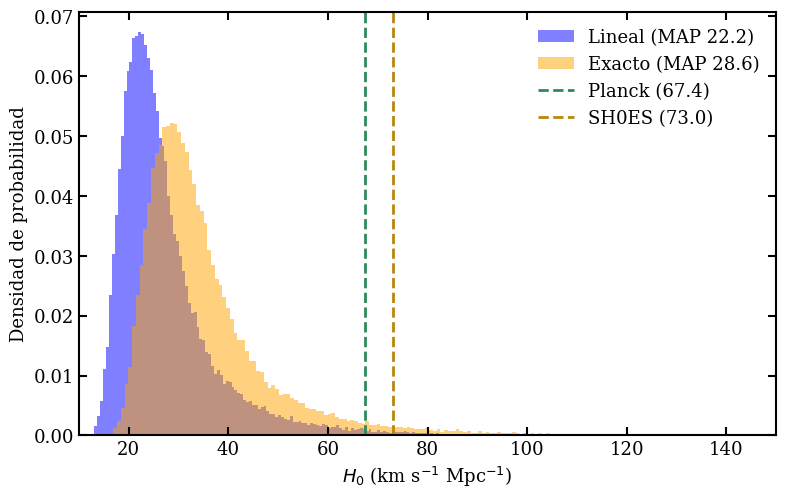

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(H0_lin, bins=200, density=True, alpha=0.5, color="blue", label=f"Lineal (MAP {map_lin:.1f})")
ax.hist(H0_ex, bins=200, density=True, alpha=0.5, color="orange", label=f"Exacto (MAP {map_ex:.1f})")
ax.axvline(H0_PLANCK, color="seagreen", ls="--", lw=2, label=f"Planck ({H0_PLANCK})")
ax.axvline(H0_SHOES, color="darkgoldenrod", ls="--", lw=2, label=f"SH0ES ({H0_SHOES})")
ax.set_xlim(10, 150)
ax.set_xlabel(r"$H_0$ (km s$^{-1}$ Mpc$^{-1}$)"); ax.set_ylabel("Densidad de probabilidad")
ax.legend(frameon=False)
plt.show()

## 2. Restringiendo a la posición de la llamarada

Si de verdad la llamarada y la señal gravitacional tienen el mismo origen, solo importan las muestras del posterior **compatibles con el punto del cielo de ZTF**. Se usa una caja en el cielo de 11° de lado (≈ 0,19 rad; está entre las cajas de 8,6° y 11,5° del cuaderno 01) y se conservan las distancias de las muestras cuyos `ra` y `dec` caen dentro de ella.

Obsérvese que la restricción **no** acerca la distribución de distancias a la de ZTF (≈ 2 443 Mpc): la desplaza ligeramente hacia distancias mayores. Es una consecuencia de la correlación entre posición y distancia en el posterior.

Muestras totales: 65,723    dentro de la caja de 11°: 5,548
Distancia mediana: completo 5297 Mpc   restringido 5869 Mpc


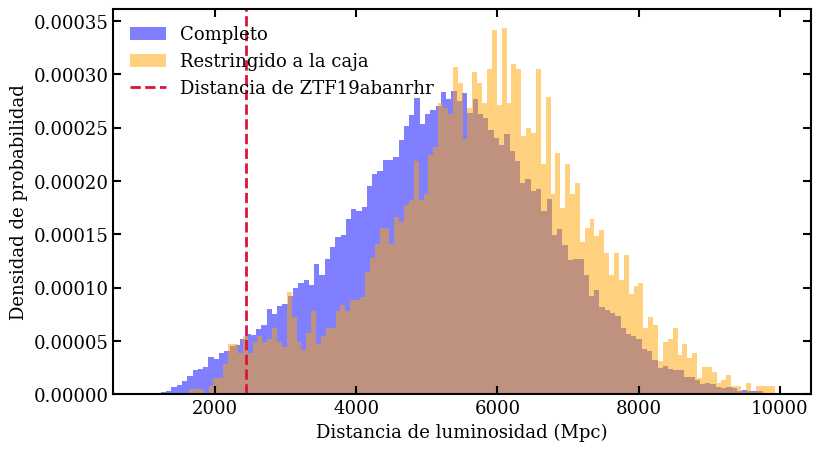

In [4]:
L_angle_deg = 11
mask = (np.abs(ra_post - tb.RA_ZTF) < np.radians(L_angle_deg / 2.0)) & \
       (np.abs(dec_post - tb.DEC_ZTF) < np.radians(L_angle_deg / 2.0))
selected_ld = distancia[mask]

print(f"Muestras totales: {len(distancia):,}    dentro de la caja de {L_angle_deg}°: {len(selected_ld):,}")
print(f"Distancia mediana: completo {np.median(distancia):.0f} Mpc   restringido {np.median(selected_ld):.0f} Mpc")

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(distancia, bins=120, density=True, alpha=0.5, color="blue", label="Completo")
ax.hist(selected_ld, bins=120, density=True, alpha=0.5, color="orange", label="Restringido a la caja")
ax.axvline(tb.DL_ZTF, color="crimson", ls="--", lw=2, label="Distancia de ZTF19abanrhr")
ax.set_xlabel("Distancia de luminosidad (Mpc)"); ax.set_ylabel("Densidad de probabilidad")
ax.legend(frameon=False)
plt.show()

## 3. Prior uniforme en $H_0$

Al transformar $d_L \to H_0\propto 1/d_L$ cambia también el prior implícito: el prior de LIGO-Virgo para la distancia crece como $d_L^2$, y al pasar a $H_0$ eso deforma la distribución (el *jacobiano* del cambio de variable penaliza los $H_0$ altos).

Para obtener el resultado que se tendría con un prior **uniforme en $H_0$** no se cambia la fórmula: se **repesan** las muestras. Cada muestra recibe un peso proporcional a $H_0^2$, que cancela esa deformación.

In [5]:
x_grid = np.linspace(10, 150, 1000)

def curvas(H0_muestras):
    # Densidad con el prior heredado de la distancia y con prior uniforme en H0 (peso H0^2)
    pdf_heredado = gaussian_kde(H0_muestras).evaluate(x_grid)
    pdf_uniforme = gaussian_kde(H0_muestras, weights=H0_muestras**2).evaluate(x_grid)
    return pdf_heredado, pdf_uniforme

def intervalo_90(x, pdf):
    # Intervalo de credibilidad del 90 %: donde la distribución acumulada cruza el 5 % y el 95 %
    cdf = np.cumsum(pdf)
    cdf = cdf / cdf[-1]
    return x[np.searchsorted(cdf, 0.05)], x[np.searchsorted(cdf, 0.95)]

casos = {}
for nombre, dl in [("Completa", distancia), ("Restringida a ZTF", selected_ld)]:
    pdf_h, pdf_u = curvas(H0_exacto(dl))
    for prior, pdf in [("prior heredado", pdf_h), ("prior uniforme", pdf_u)]:
        casos[(nombre, prior)] = (x_grid[np.argmax(pdf)], *intervalo_90(x_grid, pdf), pdf)

print(f"{'Muestras':<20} {'Prior en H0':<16} {'MAP':>6} {'IC 90 %':>16}")
for (nombre, prior), (mp, lo, hi, _) in casos.items():
    print(f"{nombre:<20} {prior:<16} {mp:6.1f}   [{lo:5.1f}, {hi:5.1f}]")

Muestras             Prior en H0         MAP          IC 90 %
Completa             prior heredado     28.6   [ 21.8,  61.9]
Completa             prior uniforme     32.3   [ 24.0,  94.8]
Restringida a ZTF    prior heredado     27.0   [ 20.2,  55.7]
Restringida a ZTF    prior uniforme     29.3   [ 21.4,  75.9]


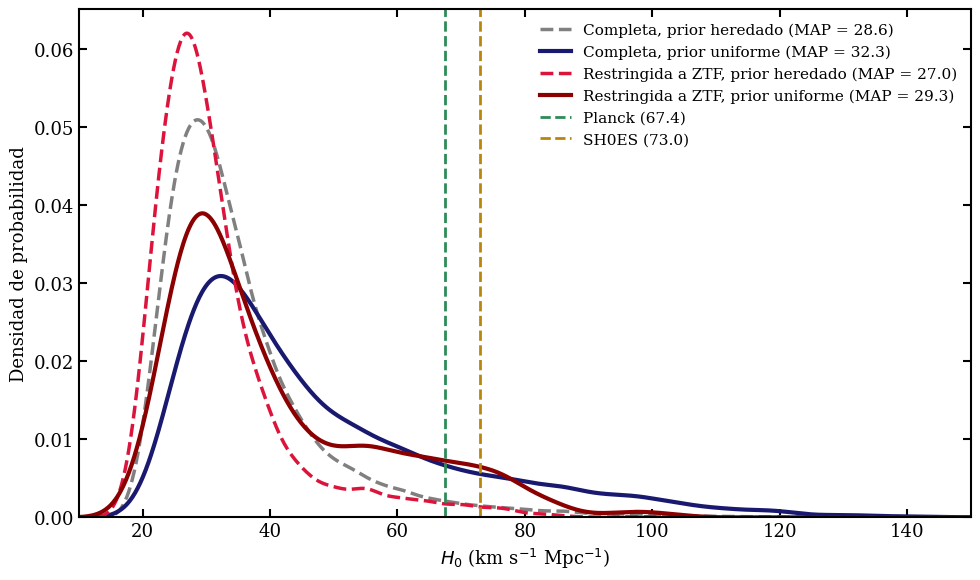

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
estilos = {
    ("Completa", "prior heredado"): dict(color="gray", ls="--", lw=2.5),
    ("Completa", "prior uniforme"): dict(color="midnightblue", ls="-", lw=3),
    ("Restringida a ZTF", "prior heredado"): dict(color="crimson", ls="--", lw=2.5),
    ("Restringida a ZTF", "prior uniforme"): dict(color="darkred", ls="-", lw=3),
}
for key, (mp, lo, hi, pdf) in casos.items():
    ax.plot(x_grid, pdf, label=f"{key[0]}, {key[1]} (MAP = {mp:.1f})", **estilos[key])
ax.axvline(H0_PLANCK, color="seagreen", ls="--", lw=2, label=f"Planck ({H0_PLANCK})")
ax.axvline(H0_SHOES, color="darkgoldenrod", ls="--", lw=2, label=f"SH0ES ({H0_SHOES})")
ax.set_xlim(10, 150); ax.set_ylim(bottom=0)
ax.set_xlabel(r"$H_0$ (km s$^{-1}$ Mpc$^{-1}$)"); ax.set_ylabel("Densidad de probabilidad")
ax.legend(frameon=False, fontsize=11)
plt.tight_layout()
plt.show()

## 4. Resultados

Valor más probable (MAP) e intervalo de credibilidad del 90 % de $H_0$, en km s⁻¹ Mpc⁻¹:

| Muestras | Prior en $H_0$ | MAP [5 %, 95 %] |
|---|---|---|
| Completa | heredado de $d_L$ | 28,6 [21,8; 61,9] |
| Completa | uniforme | 32,3 [24,0; 94,8] |
| Restringida a ZTF | heredado de $d_L$ | 27,0 [20,2; 55,7] |
| Restringida a ZTF | uniforme | 29,3 [21,4; 75,9] |

(Coinciden con la ejecución de arriba y con la Tabla 3 de la memoria.)

**Lectura.**
* El valor más probable queda en ≈ 27–32, **menos de la mitad** de los valores aceptados (67–73), con cualquiera de los dos priors y con o sin restricción al cielo. La causa es directa: la mediana de la distancia del posterior (≈ 5 300 Mpc) es más del doble de la que corresponde a $z=0{,}438$ en un universo con $H_0=70$ (≈ 2 420 Mpc).
* Con el prior uniforme el intervalo del 90 % sí llega a contener los valores de Planck y SH0ES (el límite superior sube a ≈ 76–95), pero el grueso de la probabilidad sigue en valores cosmológicamente poco plausibles.
* Es una prueba más, junto con el análisis de los cuadernos 01 y 02, de que la asociación entre GW190521 y la llamarada no queda bien respaldada; también encaja con que, al venir de una única fuente con $d_L$ muy incierta, la medida de $H_0$ tenga una incertidumbre grande.